In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Lagankhel Data Analysis and Visualization of last 365 days

In [2]:
df365 = pd.read_csv('cleaned_MidBanesworLast365days.csv')
df365

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,21.313750,c,2025-11-25 14:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2025-11-25,14:45:00
1,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,21.889250,c,2025-11-25 15:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2025-11-25,15:45:00
2,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,21.304528,c,2025-11-25 16:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2025-11-25,16:45:00
3,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,20.175167,c,2025-11-25 17:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2025-11-25,17:45:00
4,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,20.141000,c,2025-11-25 18:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2025-11-25,18:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,13.735167,c,2026-01-06 06:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-01-06,06:45:00
996,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,13.748764,c,2026-01-06 07:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-01-06,07:45:00
997,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,14.127181,c,2026-01-06 08:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-01-06,08:45:00
998,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,15.200500,c,2026-01-06 09:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-01-06,09:45:00


In [3]:
df365.columns

Index(['location_id', 'location_name', 'parameter', 'value', 'unit',
       'datetimeLocal', 'timezone', 'latitude', 'longitude', 'owner_name',
       'provider', 'date', 'time'],
      dtype='str')

In [4]:
# Convert the date column to a proper datetime value
df365["date"] = pd.to_datetime(df365["date"])

# Group records by date and calculate the daily mean temperature
daily_mean = (
    df365.groupby("date", as_index=False)
      .agg(
          daily_mean_value=("value", "mean"),
          observation_count=("value", "count"),
          location_id=("location_id", "first"),
          location_name=("location_name", "first"),
          parameter=("parameter", "first"),
          unit=("unit", "first"),
          timezone=("timezone", "first"),
          latitude=("latitude", "first"),
          longitude=("longitude", "first"),
          owner_name=("owner_name", "first"),
          provider=("provider", "first"),
      )
)

# Arrange columns in a clear order
daily_mean = daily_mean[
    [
        "date", "location_id", "location_name", "parameter",
        "daily_mean_value", "unit", "observation_count",
        "timezone", "latitude", "longitude", "owner_name", "provider",
    ]
]

In [5]:
daily_mean

,date,location_id,location_name,parameter,daily_mean_value,unit,observation_count,timezone,latitude,longitude,owner_name,provider
0,2025-11-25,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,20.111886,c,10,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient
1,2025-11-26,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,19.222170,c,24,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient
2,2025-11-27,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,19.785275,c,24,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient
3,2025-11-28,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,19.693699,c,24,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient
4,2025-11-29,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,19.501328,c,24,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient
5,2025-11-30,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,19.352755,c,24,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient
6,2025-12-01,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,19.599573,c,23,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient
7,2025-12-02,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,19.444856,c,24,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient
8,2025-12-03,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,19.693401,c,24,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient
9,2025-12-04,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,19.628852,c,24,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient


/tmp/ipykernel_12866/1693882114.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


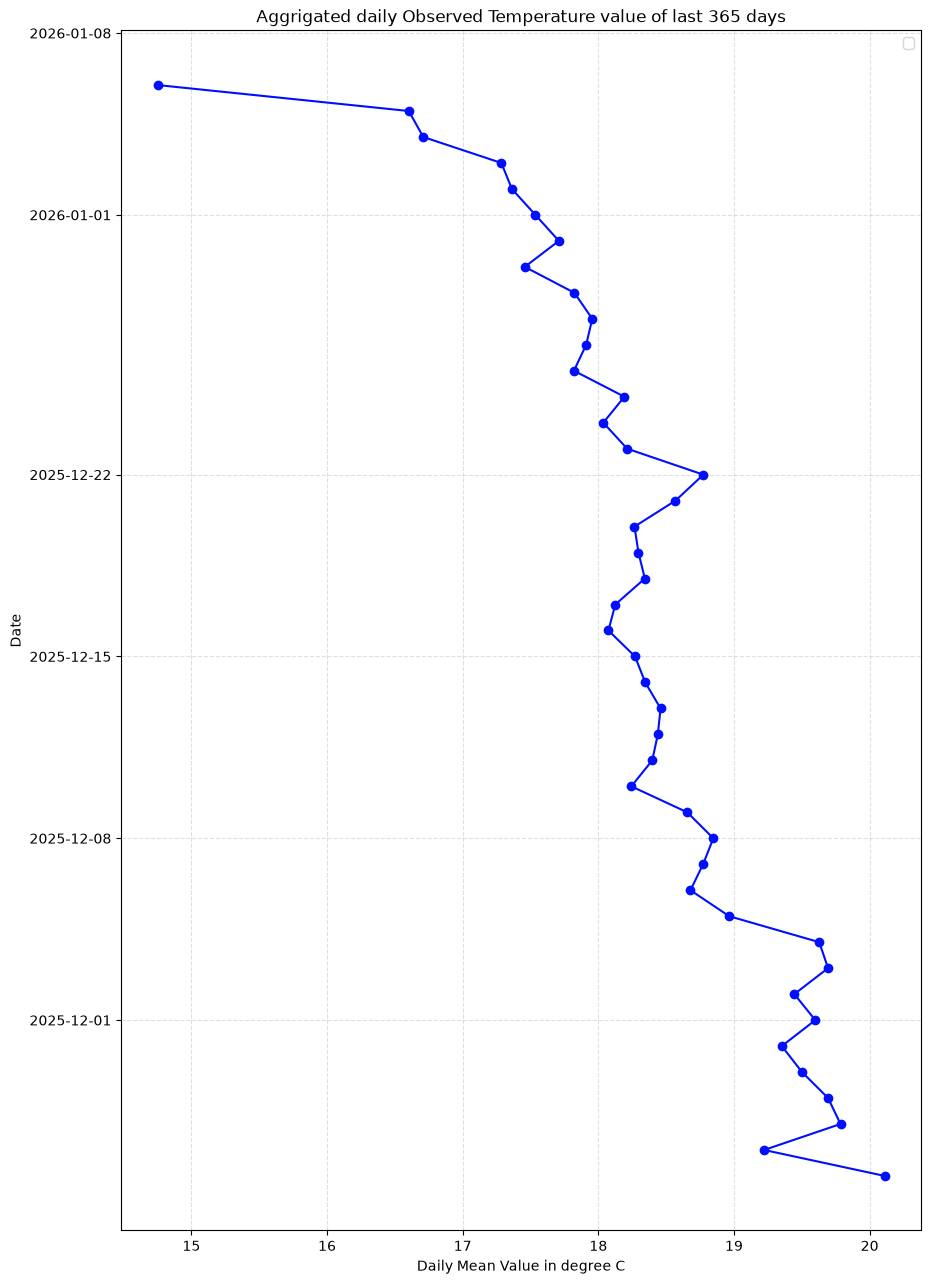

In [6]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_mean['daily_mean_value'], daily_mean['date'], color ='#000fff', marker='o')
plt.xlabel('Daily Mean Value in degree C')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed Temperature value of last 365 days")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 2. Data analysis and Visualization of last 30 days

In [7]:
df30 = pd.read_csv('cleaned_MidBanesworLast30days.csv')
df30

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,26.5,c,2026-09-12 06:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-09-12,06:45:00
1,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,26.7,c,2026-09-12 07:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-09-12,07:45:00
2,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,27.6,c,2026-09-12 08:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-09-12,08:45:00
3,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,28.7,c,2026-09-12 09:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-09-12,09:45:00
4,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,29.7,c,2026-09-12 10:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-09-12,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
715,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,23.4,c,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-12,01:45:00
716,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,23.1,c,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-12,02:45:00
717,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,22.9,c,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-12,03:45:00
718,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,22.8,c,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-12,04:45:00


In [8]:
df30.columns

Index(['location_id', 'location_name', 'parameter', 'value', 'unit',
       'datetimeLocal', 'timezone', 'latitude', 'longitude', 'owner_name',
       'provider', 'date', 'time'],
      dtype='str')

In [9]:
# Convert the date column to a proper datetime value
df30["date"] = pd.to_datetime(df30["date"])

# Group records by date and calculate the daily mean temperature
daily_mean = (
    df30.groupby("date", as_index=False)
      .agg(
          daily_mean_value=("value", "mean"),
          observation_count=("value", "count"),
          location_id=("location_id", "first"),
          location_name=("location_name", "first"),
          parameter=("parameter", "first"),
          unit=("unit", "first"),
          timezone=("timezone", "first"),
          latitude=("latitude", "first"),
          longitude=("longitude", "first"),
          owner_name=("owner_name", "first"),
          provider=("provider", "first"),
      )
)

# Arrange columns in a clear order
daily_mean = daily_mean[
    [
        "date", "location_id", "location_name", "parameter",
        "daily_mean_value", "unit", "observation_count",
        "timezone", "latitude", "longitude", "owner_name", "provider",
    ]
]

In [10]:
daily_mean

,date,location_id,location_name,parameter,daily_mean_value,unit,observation_count,timezone,latitude,longitude,owner_name,provider
0,2026-09-12,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,28.977778,c,18,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient
1,2026-09-13,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,28.358333,c,24,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient
2,2026-09-14,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,27.683333,c,24,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient
3,2026-09-15,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,27.716667,c,24,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient
4,2026-09-16,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,27.562500,c,24,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient
5,2026-09-17,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,27.775000,c,24,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient
6,2026-09-18,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,27.654167,c,24,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient
7,2026-09-19,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,27.620833,c,24,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient
8,2026-09-20,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,27.770833,c,24,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient
9,2026-09-21,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,27.637500,c,24,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient


/tmp/ipykernel_12866/3570141088.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


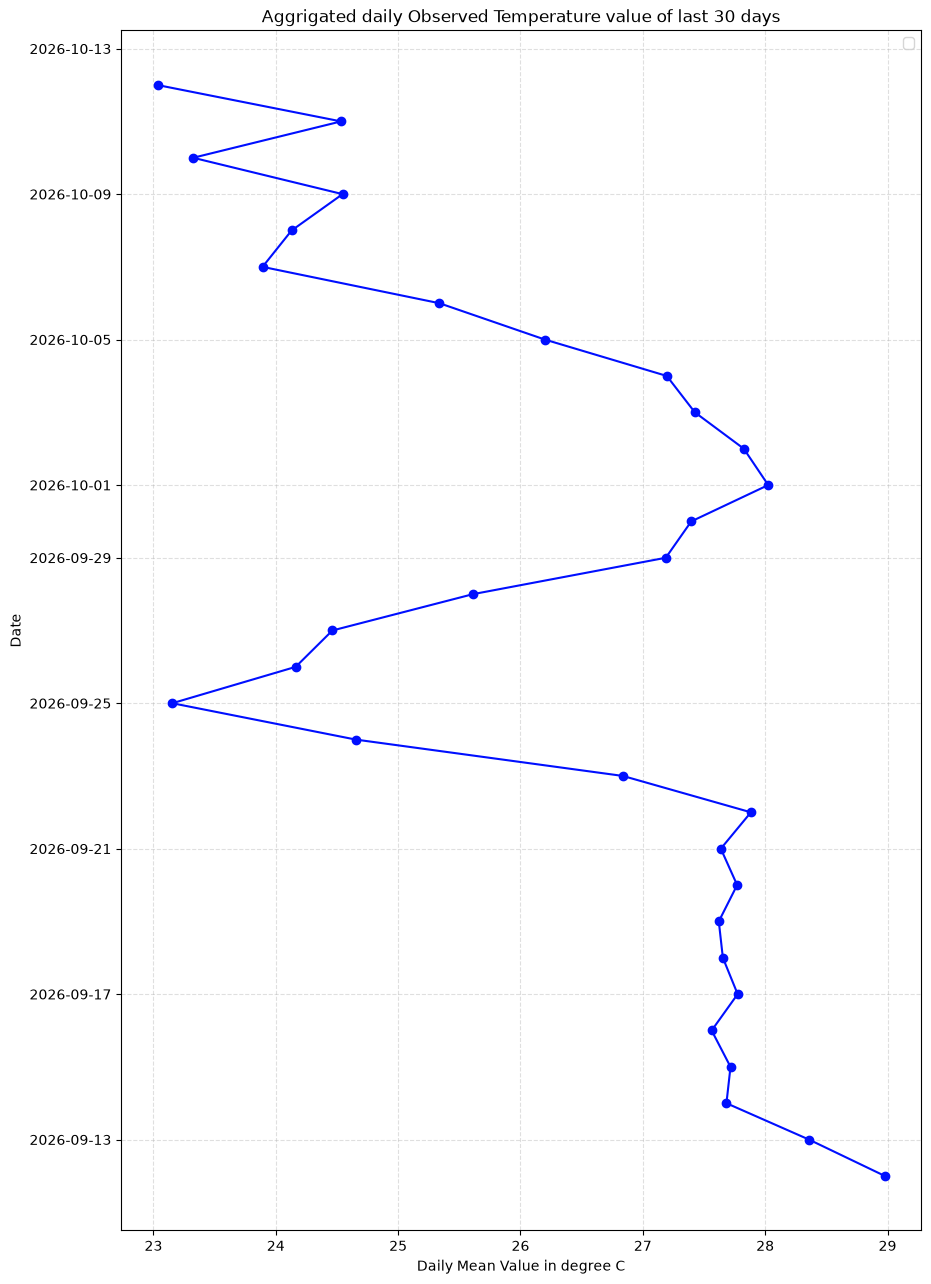

In [11]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_mean['daily_mean_value'], daily_mean['date'], color ='#000fff', marker='o')
plt.xlabel('Daily Mean Value in degree C')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed Temperature value of last 30 days")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 3. Data analysis and Visualization of last 1 week

In [12]:
df7 = pd.read_csv('cleaned_MidBanesworLast7days.csv')
df7

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,24.9,c,2026-10-05 06:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-05,06:45:00
1,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,25.2,c,2026-10-05 07:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-05,07:45:00
2,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,26.0,c,2026-10-05 08:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-05,08:45:00
3,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,26.5,c,2026-10-05 09:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-05,09:45:00
4,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,27.6,c,2026-10-05 10:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-05,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,23.4,c,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-12,01:45:00
164,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,23.1,c,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-12,02:45:00
165,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,22.9,c,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-12,03:45:00
166,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,22.8,c,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-12,04:45:00


In [13]:
# Convert the date column to a proper datetime value
df7["date"] = pd.to_datetime(df7["date"])

# Group records by date and calculate the daily mean temperature
daily_mean = (
    df7.groupby("date", as_index=False)
      .agg(
          daily_mean_value=("value", "mean"),
          observation_count=("value", "count"),
          location_id=("location_id", "first"),
          location_name=("location_name", "first"),
          parameter=("parameter", "first"),
          unit=("unit", "first"),
          timezone=("timezone", "first"),
          latitude=("latitude", "first"),
          longitude=("longitude", "first"),
          owner_name=("owner_name", "first"),
          provider=("provider", "first"),
      )
)

# Arrange columns in a clear order
daily_mean = daily_mean[
    [
        "date", "location_id", "location_name", "parameter",
        "daily_mean_value", "unit", "observation_count",
        "timezone", "latitude", "longitude", "owner_name", "provider",
    ]
]


In [14]:
daily_mean

,date,location_id,location_name,parameter,daily_mean_value,unit,observation_count,timezone,latitude,longitude,owner_name,provider
0,2026-10-05,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,26.455556,c,18,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient
1,2026-10-06,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,25.337500,c,24,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient
2,2026-10-07,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,23.891667,c,24,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient
3,2026-10-08,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,24.129167,c,24,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient
4,2026-10-09,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,24.545833,c,24,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient
5,2026-10-10,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,23.325000,c,24,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient
6,2026-10-11,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,24.533333,c,24,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient
7,2026-10-12,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,23.033333,c,6,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient


/tmp/ipykernel_12866/3647158116.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


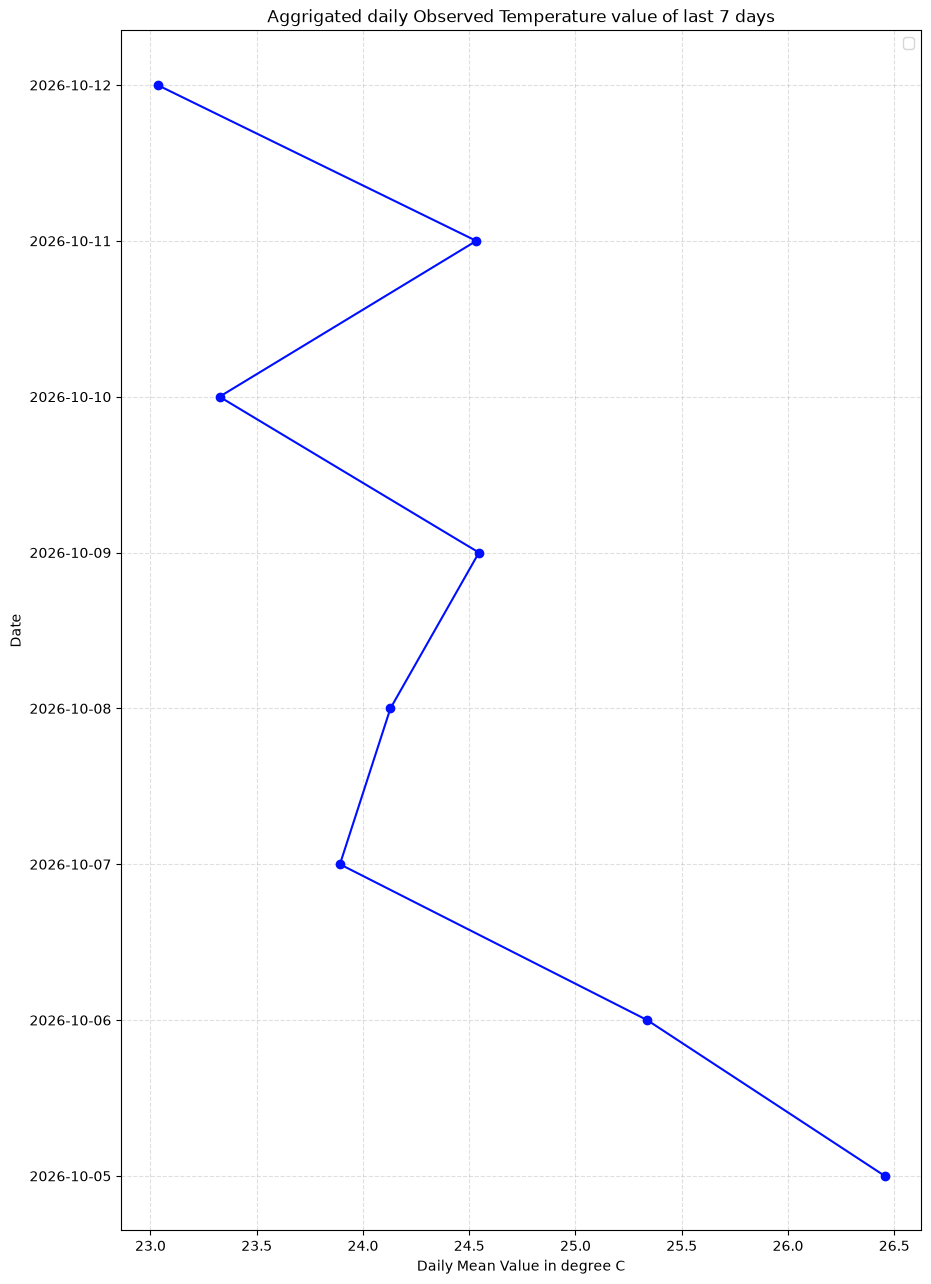

In [15]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_mean['daily_mean_value'], daily_mean['date'], color ='#000fff', marker='o')
plt.xlabel('Daily Mean Value in degree C')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed Temperature value of last 7 days")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 4. Data Analysis and Visualization of last 24 hours

In [16]:
df24 = pd.read_csv('cleaned_MidBanesworLast24hours.csv')
df24

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,22.2,c,2026-10-11 06:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,06:45:00
1,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,22.6,c,2026-10-11 07:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,07:45:00
2,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,23.5,c,2026-10-11 08:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,08:45:00
3,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,24.6,c,2026-10-11 09:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,09:45:00
4,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,25.5,c,2026-10-11 10:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,10:45:00
5,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,26.3,c,2026-10-11 11:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,11:45:00
6,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,27.0,c,2026-10-11 12:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,12:45:00
7,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,27.3,c,2026-10-11 13:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,13:45:00
8,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,27.3,c,2026-10-11 14:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,14:45:00
9,6142022,Mid Baneshwor (SC-39)-GD Labs,temperature,27.1,c,2026-10-11 15:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,15:45:00


In [17]:
df24.columns

Index(['location_id', 'location_name', 'parameter', 'value', 'unit',
       'datetimeLocal', 'timezone', 'latitude', 'longitude', 'owner_name',
       'provider', 'date', 'time'],
      dtype='str')

/tmp/ipykernel_12866/318776006.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


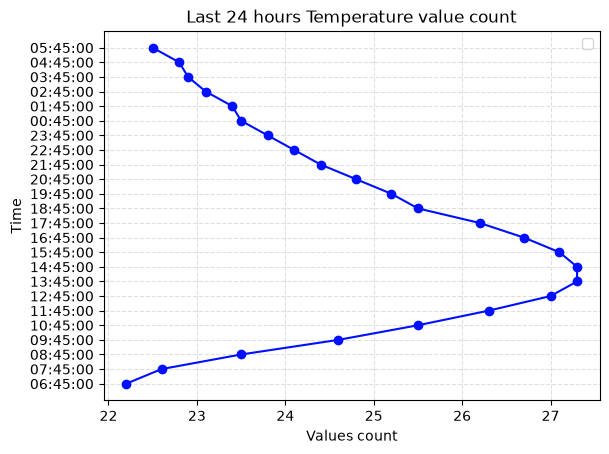

In [18]:
# Line Plot
plt.plot(df24['value'], df24['time'], color='#000fff', marker='o')
plt.xlabel('Values count')
plt.ylabel('Time')
plt.title('Last 24 hours Temperature value count')
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()